# Simulating the BER and FER Performance of a Decoder and Their Confidence Intervals

This code is provided as supplementary material of the lecture Channel Coding - Graph-based Codes.

This code illustrates
* Carrying out FER and BER Simulations
* Calculating and Displaying Confidence Intervalks

In [29]:
import numpy as np
import sympy as sp
import shutil
from tqdm.notebook import tqdm
from scipy.stats import norm


import matplotlib
import matplotlib.pyplot as plt

# plotting options 
font = {'size'   : 16}
plt.rc('font', **font)
plt.rc('text', usetex=True if shutil.which('latex') else False)

matplotlib.rc('figure', figsize=(18, 6) )

In [23]:
# define Q function and its inverse
Q    = lambda x: norm.sf(x)    # Q(x) = 1 - Φ(x)
Qinv = lambda p: norm.isf(p)   # inverse Q function

Specify code via its generator matrix $\boldsymbol{G}$. For the example, we use a random generator matrix or we can select the $(7,4)$ Hamming code.

In [32]:
# specify code by its generator matrix
G = np.array([[1, 0, 0, 0, 1, 1, 0],
              [0, 1, 0, 0, 1, 0, 1],
              [0, 0, 1, 0, 0, 1, 1]])

# random systematic generator matrix G = [I | P] with random 6x6 parity part P
G = np.hstack((np.eye(6, dtype=int), np.random.randint(0, 2, size=(6, 6))))
print("Generator matrix G:\n", G)

Generator matrix G:
 [[1 0 0 0 0 0 1 1 1 0 1 1]
 [0 1 0 0 0 0 1 0 1 1 0 0]
 [0 0 1 0 0 0 1 1 0 0 1 0]
 [0 0 0 1 0 0 1 1 0 1 1 1]
 [0 0 0 0 1 0 0 0 0 0 1 1]
 [0 0 0 0 0 1 0 1 0 0 0 1]]


Get parameters of the code and construct table with codewords.

In [33]:
# get parameters k and n of the code
k = G.shape[0]
n = G.shape[1]

# generate table of all codewords
# GF(2) operations are obtained by calculating modulo-2
u = np.array([[(i >> (k - 1 - bit)) & 1 for bit in range(k)] for i in range(2**k)]) # create array of all possible codewords 
code = (u @ G) % 2

# codebook modulated to BPSK symbols, note that (-1)^x = 1 - 2*x for x in {0, 1}
code_bpsk = 1 - 2*code

### ML Decoder for the BI-AWGN Channel

We transmit over the binary-input AWGN (BI-AWGN) channel. The bits of a codeword $\boldsymbol{x}\in\mathcal{C}$ are mapped to BPSK symbols via $0\to+1$ and $1\to-1$, i.e., the channel input is $(-1)^{x_t}=1-2x_t$ (in the code this is `code_bpsk = 1 - 2*code`). The channel output is
$$y_t = (-1)^{x_t} + n_t,\qquad n_t\sim\mathcal{N}(0,\sigma_n^2),\qquad \sigma_n^2=\frac{1}{2E_s/N_0},$$
where the symbol energy is normalized to $E_s=1$.

The maximum-likelihood (ML) decoder selects the codeword $\hat{\boldsymbol{x}}$ that maximizes the likelihood of the received vector $\boldsymbol{y}$. As the channel is memoryless and the noise is Gaussian, we have
$$
\hat{\boldsymbol{x}}
=\arg\max_{\boldsymbol{x}^{[i]}\in\mathcal{C}}\sum_{t=1}^{n}\ln f_{Y|X}\big(y_t|x_t^{[i]}\big)
=\arg\max_{\boldsymbol{x}^{[i]}\in\mathcal{C}}\sum_{t=1}^{n}\left(\ln\frac{1}{\sqrt{2\pi}\sigma_n}-\frac{\big(y_t-(-1)^{x_t^{[i]}}\big)^2}{2\sigma_n^2}\right)
=\arg\max_{\boldsymbol{x}^{[i]}\in\mathcal{C}}\sum_{t=1}^{n}-\big(y_t-(-1)^{x_t^{[i]}}\big)^2 ,
$$
where the constant term and the positive factor $1/(2\sigma_n^2)$ do not change the maximization. Expanding the square gives $y_t^2+1-2y_t(-1)^{x_t^{[i]}}$. Since $y_t^2+1$ is the same for all codewords, it can also be dropped, which yields the **correlation decoder**
$$
\hat{\boldsymbol{x}}=\arg\max_{\boldsymbol{x}^{[i]}\in\mathcal{C}}\sum_{t=1}^{n}y_t\,(-1)^{x_t^{[i]}} .
$$

Equivalently, ML decoding on the BI-AWGN channel is a minimum Euclidean distance decoder. In the simulation below, we compute the correlation of $\boldsymbol{y}$ with all $2^k$ BPSK-modulated codewords (`np.sum(code_bpsk * y, 1)`) and pick the codeword with the largest value (`np.argmax`).

In [43]:
# BI-AWGN channel
esno_dB_range = np.arange(-3, 6, 0.5) # specify Es/N0 in dB

esno_lin_range = 10**(esno_dB_range/10)

In [63]:
# calculate Monte-Carlo-Estimate of ML performance
# transmit N codewords
N = 10000

# confidence level for confidence intervals
beta = 0.95

FER_estimate = np.zeros(len(esno_lin_range))
FER_confidence_interval = np.zeros((len(esno_lin_range), 2))

BER_estimate = np.zeros(len(esno_lin_range))
BER_confidence_interval = np.zeros((len(esno_lin_range), 2))


for esno_idx, esno_lin in enumerate(tqdm(esno_lin_range)):
    # standard deviation of noise distribution
    sigma_n = np.sqrt(1 /(2*esno_lin))

    # select random codewords to be transmitted for this SNR valuer
    transmit_idx = np.random.randint(0, code.shape[0], size=N)

    # number of frame errors
    N_e = 0
    # sums needed to compute the bit error rate and its confidence interval
    B_i_sum = 0
    B_i_squared_sum = 0

    for j in range(N):
        x = code_bpsk[transmit_idx[j], :]
                
        # simulate transmission over BI-AWGN channel
        y = x + sigma_n * np.random.randn(x.shape[0])
        
        # calculate correlation with all codewords (ML Decoder)
        correlation = np.sum(code_bpsk * y, 1)        
        ML_decision_idx = np.argmax(correlation)

        # in case we make a decoding error
        if int(ML_decision_idx != transmit_idx[j]):
            N_e = N_e + 1
            # number of bit positions in which the estimated codeword differs from the transmitted one
            b_i = int(np.sum(code[ML_decision_idx, :] != code[transmit_idx[j], :]))
            B_i_sum = B_i_sum + b_i
            B_i_squared_sum = B_i_squared_sum + b_i**2

    FER_estimate[esno_idx] = N_e / N
    BER_estimate[esno_idx] = B_i_sum / (N * n)

    # calculate FER confidence interval
    a = Qinv((1 - beta) / 2) * np.sqrt(N_e * (N - N_e) / N**3)
    FER_confidence_interval[esno_idx, 0] = FER_estimate[esno_idx] - a
    FER_confidence_interval[esno_idx, 1] = FER_estimate[esno_idx] + a

    # calculate BER confidence interval
    a_tilde = Qinv((1 - beta) / 2) * np.sqrt((B_i_squared_sum / N - (B_i_sum / N)**2)) / np.sqrt(n*N)
    BER_confidence_interval[esno_idx, 0] = BER_estimate[esno_idx] - a_tilde
    BER_confidence_interval[esno_idx, 1] = BER_estimate[esno_idx] + a_tilde

    #print(f"Es/N0 = {esno_dB_range[esno_idx]:.1f} dB: Btilde = {(B_i_sum**2)/(B_i_squared_sum):.4f}")
# the normal approximation can yield negative lower bounds, which are meaningless for error rates: clip at 0
FER_confidence_interval = np.maximum(FER_confidence_interval, 0)
BER_confidence_interval = np.maximum(BER_confidence_interval, 0)
assert np.all(FER_confidence_interval >= 0) and np.all(BER_confidence_interval >= 0)

  0%|          | 0/18 [00:00<?, ?it/s]

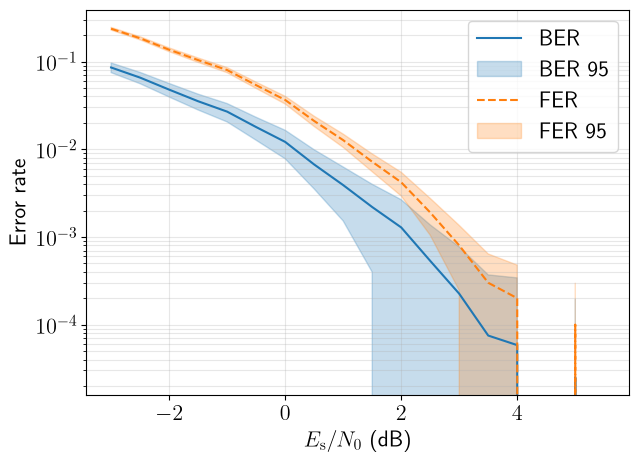

In [64]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

# BER: solid line, FER: dashed line, shaded areas show the confidence intervals
ax.semilogy(esno_dB_range, BER_estimate, '-', color='C0', label='BER')
ax.fill_between(esno_dB_range, BER_confidence_interval[:, 0], BER_confidence_interval[:, 1],
                color='C0', alpha=0.25, label=f'BER {beta:.0%} confidence interval')

ax.semilogy(esno_dB_range, FER_estimate, '--', color='C1', label='FER')
ax.fill_between(esno_dB_range, FER_confidence_interval[:, 0], FER_confidence_interval[:, 1],
                color='C1', alpha=0.25, label=f'FER {beta:.0%} confidence interval')

ax.set_xlabel(r'$E_{\mathrm{s}}/N_0$ (dB)')
ax.set_ylabel('Error rate')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.show()

# save results to a csv file (first line is a descriptor of the columns)
results = np.column_stack((esno_dB_range, FER_estimate, BER_estimate,
                           FER_confidence_interval, BER_confidence_interval))
header = 'esno_dB,fer,ber,fer_ci_lower,fer_ci_upper,ber_ci_lower,ber_ci_upper'
filename = f'BER_FER_results_n{n}_k{k}_N{N}.csv'
np.savetxt(filename, results, delimiter=',', header=header, comments='')